In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from pathlib import Path

data_path = Path('Desktop/Data/electricity-demand-forecasting/data/PJME_hourly.csv')
data = pd.read_csv(data_path)

PJ = pd.DataFrame(data)
PJ['Datetime'] = pd.to_datetime(PJ['Datetime'])
PJ.set_index('Datetime', inplace=True)
PJ.sort_index(inplace=True)
PJ.head()

,PJME_MW
Datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


In [6]:
# Time features
PJ['hour'] = PJ.index.hour
PJ['dayofweek'] = PJ.index.dayofweek
PJ['month'] = PJ.index.month
PJ['day'] = PJ.index.day
PJ['weekofyear'] = PJ.index.isocalendar().week.astype(int)

In [7]:
#Lag features

PJ['lag_1'] = PJ['PJME_MW'].shift(1)
PJ['lag_24'] = PJ['PJME_MW'].shift(24)
PJ['lag_48'] = PJ['PJME_MW'].shift(48)

In [8]:
#Rolling statistics

PJ['rolling_mean_24'] = PJ['PJME_MW'].shift(1).rolling(24).mean()

PJ.dropna(inplace=True)

In [9]:
Features = ['hour', 'dayofweek', 'month', 'day', 'weekofyear', 'lag_1', 'lag_24', 'lag_48', 'rolling_mean_24']

Target = 'PJME_MW'

x = PJ[Features]
y = PJ[Target]

In [10]:
split = int(len(PJ)*0.8)

x_train = x.iloc[:split]
x_test = x.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=6)
result = model.fit(x_train, y_train)

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

residual = y_test - forecast

lb_test = acorr_ljungbox(residual, lags=[24], return_df=True)

print(lb_test)

         lb_stat  lb_pvalue
24  32753.320507        0.0


In [13]:
forecast = model.predict(x_test)

forecast = pd.Series(forecast, index= y_test.index)

In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, forecast)
mae = mean_absolute_error(y_test, forecast)
R2_squared = r2_score(y_test,forecast)

rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test - forecast)/y_test))*100

print('Rmse:{:.2f}'.format(rmse))
print('Mape:{:.2f}'.format(mape))
print('Mae:{:.2f}'.format(mae))
print('Rsquard:{:.2f}'.format(R2_squared))

Rmse:489.13
Mape:1.18
Mae:368.55
Rsquard:0.99


In [ ]:
# The HistGradientBoosting model achieved strong predictive performance for hourly electricity demand forecasting, with MA=
# RMSe= ,... The low MAPe and R2 indicate that the model effectively captured the nonlinear temporal dynamics and daily
# cyclic patterns of electricity consumption. 


# MAe  (Average miss is small)

# On average, forecast differs from actual electricity demand by about -+369 MW. 
# considering the demand ranges approximately between 20,000 MW to 30,000 MW this error is quite small. 
# mae is 422.56 : on average, my model's prediction is off about 422 MW
# if the actual load is: 25,000 MW then prediction is within 24,577 MW to 25,423 MW
# why it matters : because utilities care about how many megawatts they may underpredict or overpredict
# underpredict = risk of insufficient generation,, overpredict - wasted generation cost
# so an average error of 422 MW for a systm around 25,000 MW demand is relatively small. 

# RMSe (Large errors are controlled)

# The model's typical error magnitude is about 645 MW. 
# electricity demand might have sudden spikes; heat waves, cold, holidays, industrial surges. based on forecasting errors.
# model is stable because the diff between MAe and RMSe is not huge.
# some large peak demand errors exist but they are not excessive.

# MAPe (Model is extremely accurate)
# forecasts are off by 1.36% less than 2% on average relative to actual demand. 
# The model predicts electricity demand with about 98,82% accuracy. 

# R2 (captures almost all demand variation)
# R2 is 0.99. 99% of the variation in electricity demand are explained by th model.
# Model captures almost all the patterns. 
# The predicted curve closely follows the real demand curve. 
# 0.99 indicates feature engineering and boosting model captured these relationships very well. 

# HistGradientBoosting works well because electricity demand data is ;non-linear, seasonal, high-volume.
# hist is performing very well for hourly electricity demand forecasting; 1. average error is low. 2. Percentage error is excellent
# 3. variability is captured almost perfectly. 4. large forecasting mistakes are limited. 

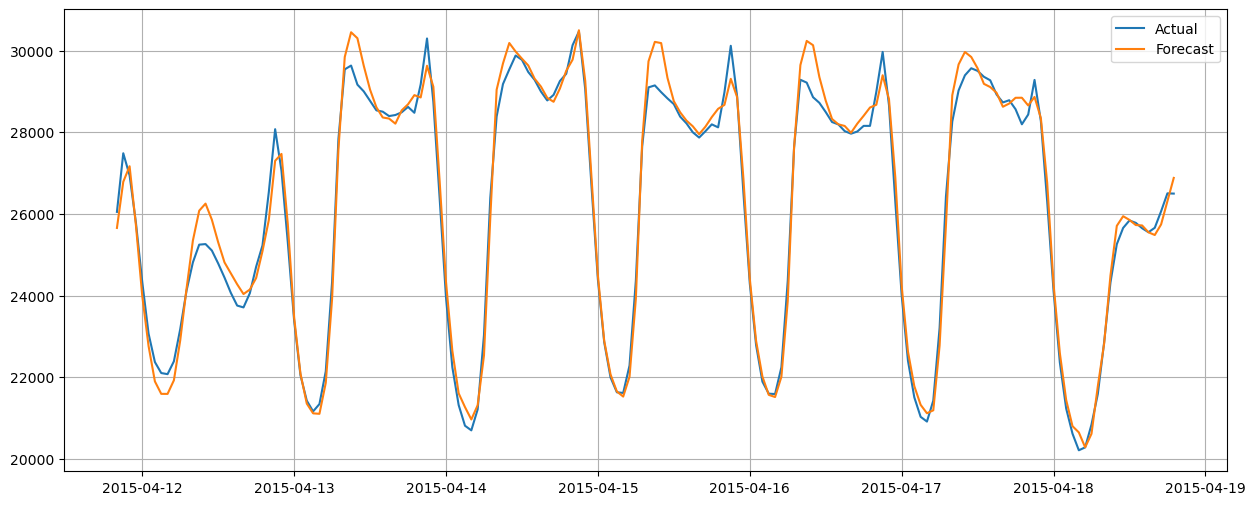

In [31]:
plt.figure(figsize=(15,6))

plt.plot(y_test[:24*7], label='Actual')
plt.plot(forecast[:24*7], label='Forecast')

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# The forecasted electricity demand closely follows the actual load profile, demonstrating that HistGradientBoosting model
# effectively learned the dynamics and daily cyclic behavior of electricity consumption. 
# Minor deviations are observed during peak demand periods, showing uncertaintity during high volatile periods.

# Daily cyclic pattern captured / behavior
# 1. night/early morning  -  Low demand
# 2. morning  - Demand rises
# 3. Afternoon/evening - Peak demand
# 4. Late night  -   demand decreases



In [13]:
PJ.shape

(145198, 12)

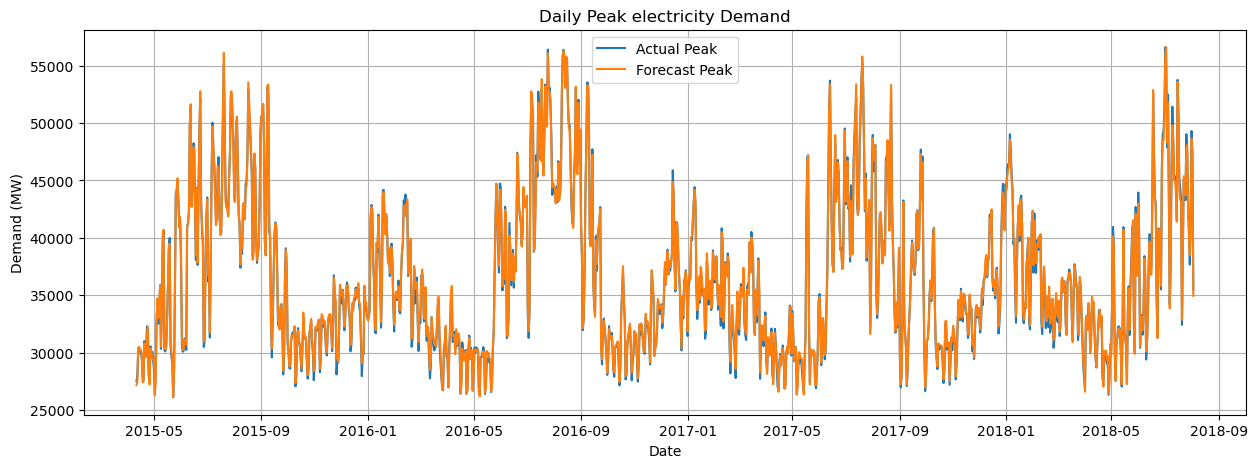

In [32]:
# plotting daily peak demand

results = pd.DataFrame({
    'Actual':y_test,
    'Forecast':forecast
})

daily_peak_actual = results['Actual'].resample('D').max()
daily_peak_forecast = results['Forecast'].resample('D').max()

plt.figure(figsize=(15,5))

plt.plot(daily_peak_actual.index, daily_peak_actual, label='Actual Peak')

plt.plot(daily_peak_forecast.index, daily_peak_forecast, label='Forecast Peak')

plt.title('Daily Peak electricity Demand')
plt.xlabel('Date')
plt.ylabel('Demand (MW)')
plt.legend()
plt.grid()

plt.show()

In [ ]:
# the demand curve shows clear repeating cycles; high peaks accur periodically, lower valleys appear between peak seasons.
# sharp spikes indicate periods of sudden high electricity usage.
# Forecast line follows most spikes, showing that histgradientboosting handles nonlinear relationship well. and
# exogenous variables probably improve peak prediction. 

# some peaks are smoother than acutal demand; cos extreme demand events are harder to predict.
# large spikes indicate; stress periods on the power grid.

In [33]:
# extreme demand periods

threshold = results['Actual'].quantile(0.95)

extreme = results[ results['Actual'] >= threshold]

print('extreme Demand Threshold:', threshold)
print('number of extreme Hours:', len(extreme))

# extreme demand accuracy is to prevent outages

extreme Demand Threshold: 43758.0
number of extreme Hours: 1452


In [ ]:
# 95th percentile, only the top 5% of all hourly electricity demand observations axceed this value.
# if Demand > 43758 is classified as an extreme demand hour.
# 1452 indicates; where power system experience many high stress load periods. increase blackout risk,
# affect grid stability, raise operating cost.
# During these times consumption becomes more nonlinear, larger errors, explians the sharp spikes.
# This also help evaluate model robustness under stress conditions. identifies risks events. seperate normal vs peak load
# behavior

In [36]:
results['Residuals'] = results['Actual']-results['Forecast']

ValueError: '_ _' is not a valid value for ls; supported values are '-', '--', '-.', ':', 'None', ' ', '', 'solid', 'dashed', 'dashdot', 'dotted'

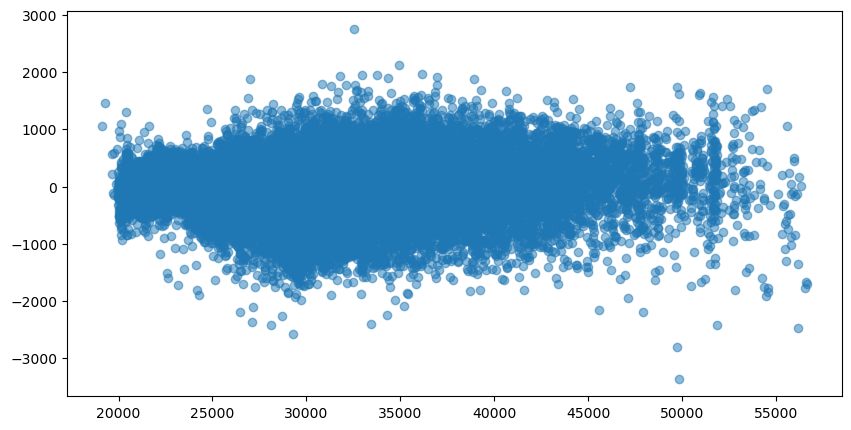

In [37]:
# Residual plot (bias + heteroscedasticity) 
 
plt.figure(figsize=(10,5))

plt.scatter(results['Forecast'], results['Residuals'], alpha=0.5)

plt.axhline(y=0, color ='red', linestyle='_ _')

plt.title('Residuals vs Forecast')
plt.xlabel('Forecast')
plt.ylabel('Residuals')

plt.grid()
plt.show()

In [ ]:
# Residuals are approximately centered around zero, explaining the absence of model bias. 
# However, the residual spread increases at higher forecast level suggesting heteroscedasticity where prediction ambuguity grows 
# during high-demand periods.

# Dense center region - most hours are normal demand
# Wider spread at high demand - peak loads harder to predict (peak demand)
# some large outliers - extreme conditions or events/ weather effects must have happened at that time
# no obvious curve - model captured nonlinear demand patterns. 

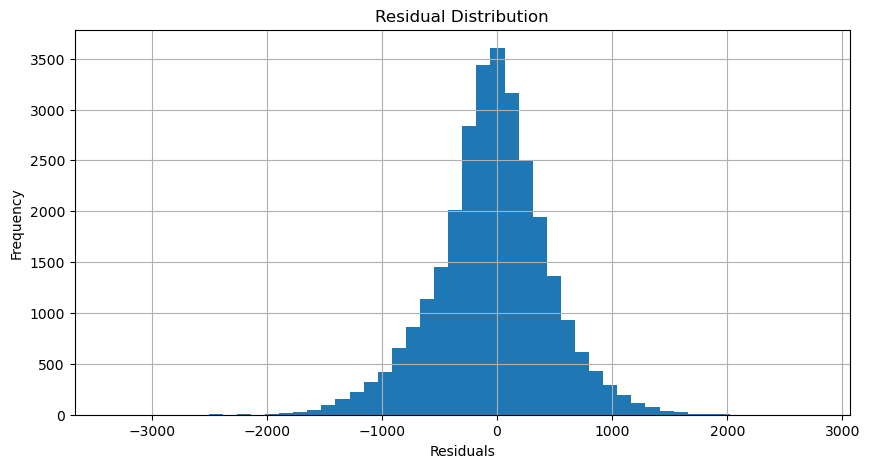

In [38]:
# Residual Distribution

plt.figure(figsize=(10,5))

plt.hist(results['Residuals'], bins=50)

plt.title('Residual Distribution')
plt.xlabel('Residuals')
plt.ylabel('Frequency')

plt.grid()
plt.show()

In [ ]:
# error distribution is approximately normal.
# The model generalizes well. 
# no strong evidence of overforecasting or underforecasting.
# most predictions errors are small.

# the residual distribution in histgradientboosting model is approximately symmetric and centered around zero, indicating 
# prediction errors are largely unbiased. and do not affect overall model performance. 

ValueError: '_ _' is not a valid value for ls; supported values are '-', '--', '-.', ':', 'None', ' ', '', 'solid', 'dashed', 'dashdot', 'dotted'

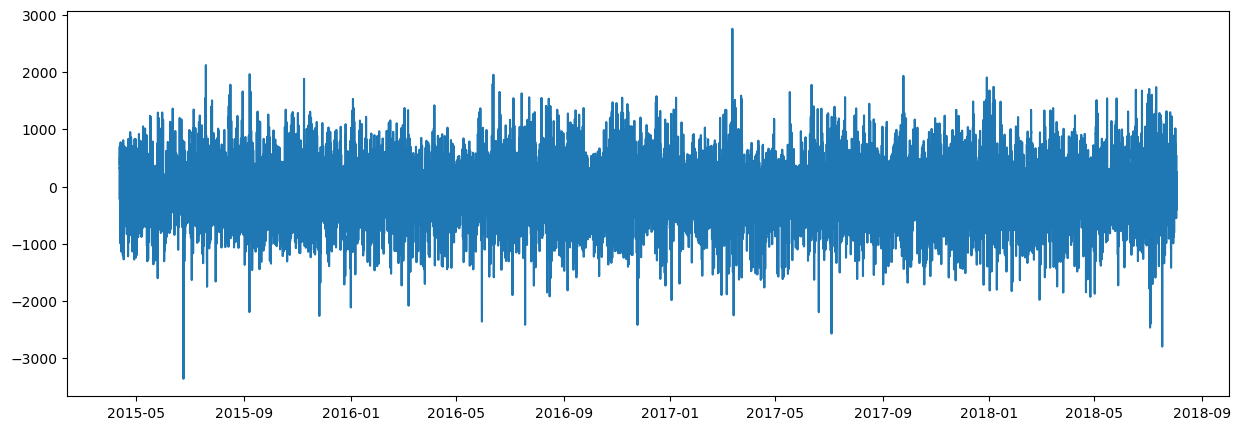

In [39]:
# Residuals Over Time ... important

plt.figure(figsize=(15,5))

plt.plot(results.index, results['Residuals'])

plt.axhline(y=0, color = 'red', linestyle='_ _')

plt.title('Residuals Over Time')
plt.xlabel('Time')
plt.ylabel('Residuals')

plt.grid()
plt.show()

In [ ]:
# Interpretation

# Residuals fluctuate around zero. Most errors are within approximately -1400 MW to +1400 MW.
# There are few spikes reaching -3000 MW and +3000 MW. 

# The residuals are randomly disributed arounded zero, indicating that the HistGradientBoosting model effectively captured the
# underlying electricity demand dynmaics. Occasional large residual spikes correspond to extreme demand events likely influenced by 
# external factors such as weather anomalies or holidays. 
# most importantly electricity demand is not consistently overestimate or underestimate. it is stable.

ValueError: '_ _' is not a valid value for ls; supported values are '-', '--', '-.', ':', 'None', ' ', '', 'solid', 'dashed', 'dashdot', 'dotted'

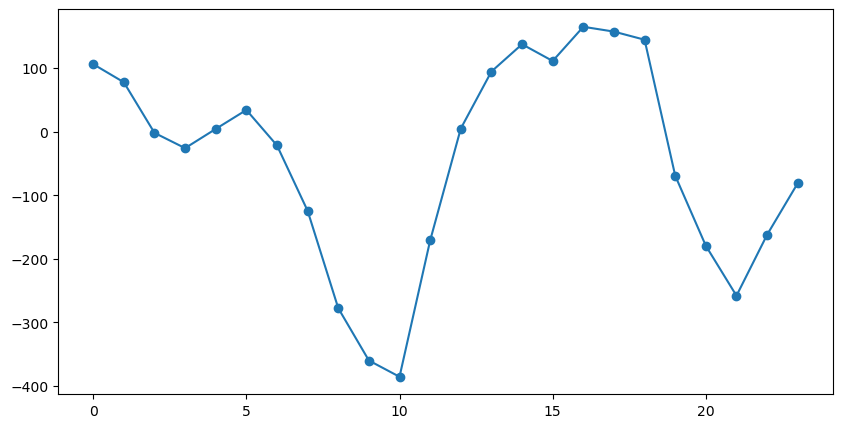

In [40]:
# important

results['Hour'] = results.index.hour

hourly_residuals = results.groupby('Hour')['Residuals'].mean()

plt.figure(figsize=(10,5))
plt.plot(hourly_residuals.index, hourly_residuals.values, marker='o')

plt.axhline(y=0, color='red', linestyle='_ _')

plt.title('Average Residual by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Mean Residuals')

plt.grid()
plt.show()

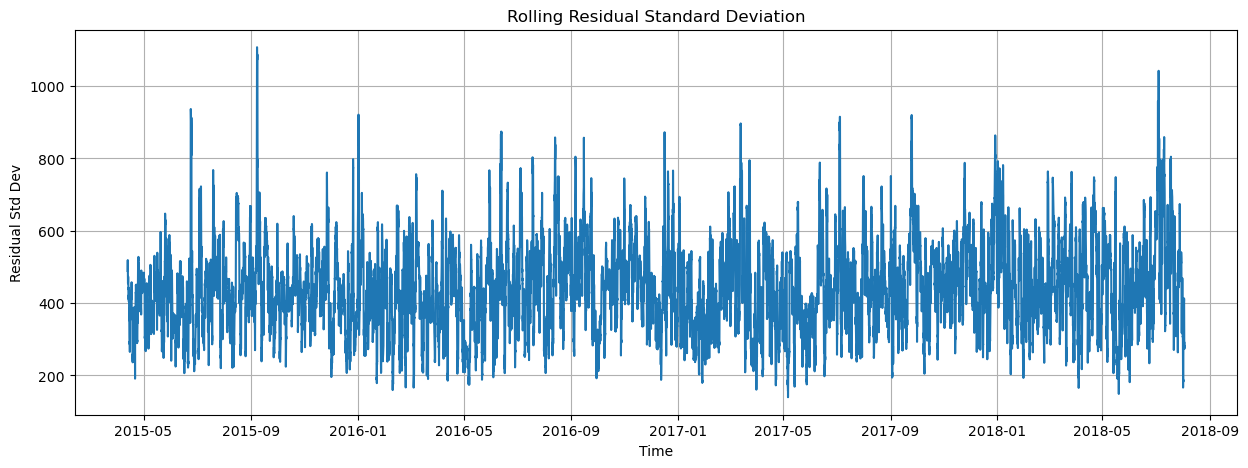

In [41]:
# Rolling Residual Variance (Checking heteroscedasticity over time)... important

rolling_std = results['Residuals'].rolling(24).std()

plt.figure(figsize=(15,5))
plt.plot(rolling_std)

plt.title('Rolling Residual Standard Deviation')
plt.xlabel('Time')
plt.ylabel('Residual Std Dev')

plt.grid()
plt.show()

In [ ]:
# Rolling Residual Standard Deviation over time checks whether the forecasting errors remain stable across time

# Residual is mostly stable range. 
# forecast accuracy is reasonably consistent across time.
# Some period show sudden spikes upward

# check heteroscedasticity
# constant error variance; homoscedasticity assumption is not violated.
# model assumptions are good. 
# Residual variance is stable. 

In [1]:
# POLICY ACTIONS (POLICY MAKeR)

# 1. Implement time of use pricing
# higher tariffs during peak hours. lower tariffs during off peak hours. to encourage consumers to shift usage away from peak 
# periods.
# encourage industries, commercial buildings, large consumers to reduce usage during peak demands. to prevent blackouts, 
# reduce grid stress

# 2. ReneWABLe eNeRGY INTeGRATION
# solar generation, wind generation, hydro scheduling
# determine when batteries should charge, when stored electricity should discharge, during evening peaks. 

# electricity management company must be well equiped to prevent blackouts during extreme  weatherconditions that may disrupt 
# transformers failures, voltage instability, overloads.
# households must have backup generators or plant before peak demand occurs. 
